Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
Loaded: 2260 × 13
Dedup: 2260 → 2200

=== BY PLATFORM ===
             n  median_likes  median_shares  median_comments
platform                                                    
Tiktok     390          44.0            8.0              4.0
Instagram  595          37.0            6.0              3.0
Twitter    726          32.0            5.0              3.0
Facebook   370          26.0            5.0              2.0
Linkedin   119          20.0            3.0              2.0

=== BY SENTIMENT ===
             n  median_likes  median_shares  median_comments
sentiment                                                   
Negative   636          32.0            5.0              3.0
Neutral    652          28.0            4.5              2.0
Positive   879          39.0            7.0              3.0

=== BY DAY OF WEEK ===
               n  median_likes
da

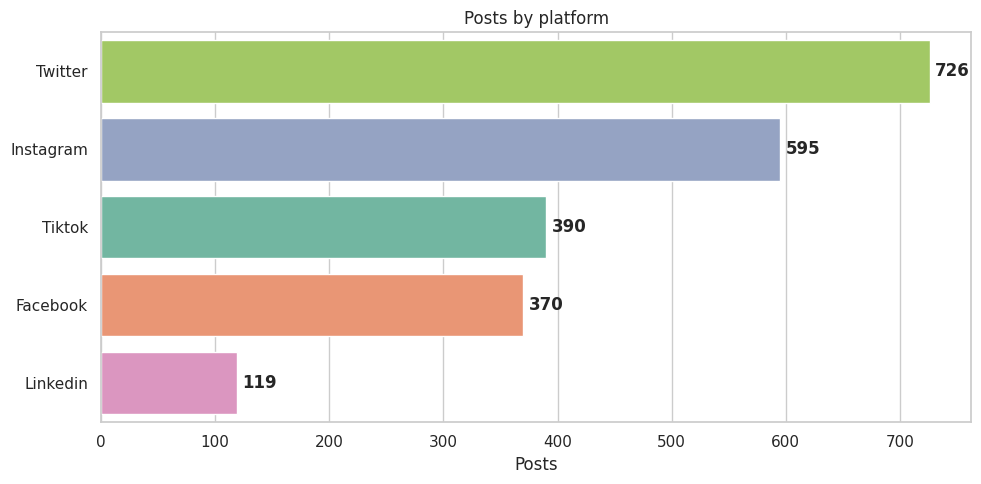

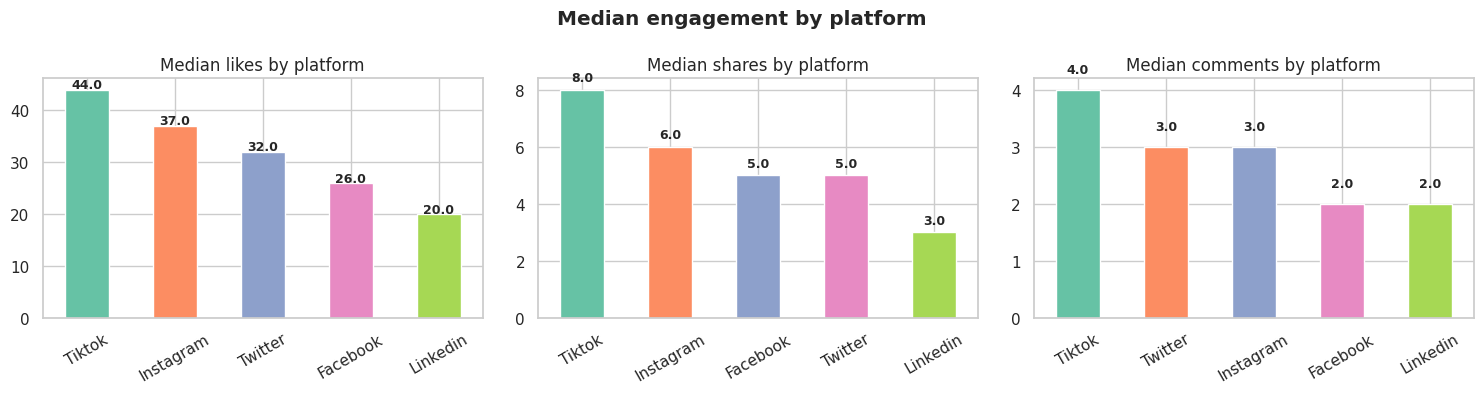

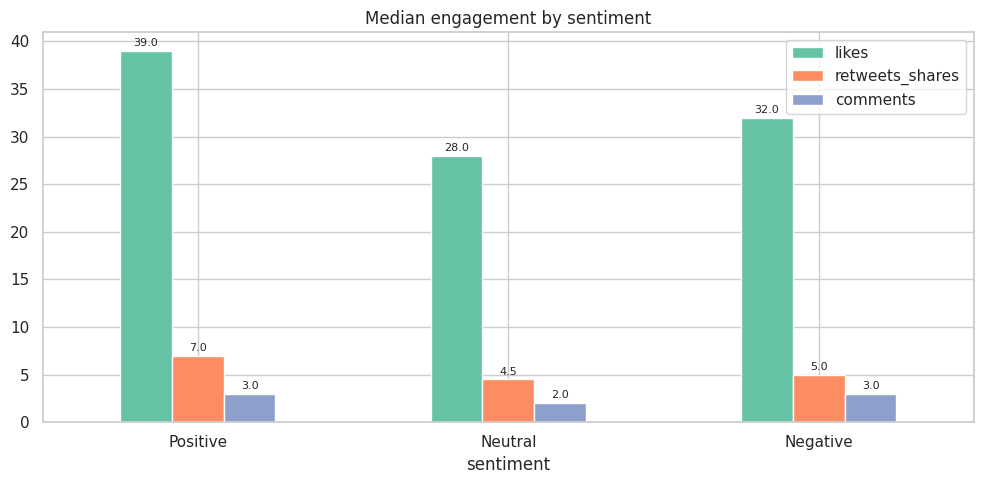

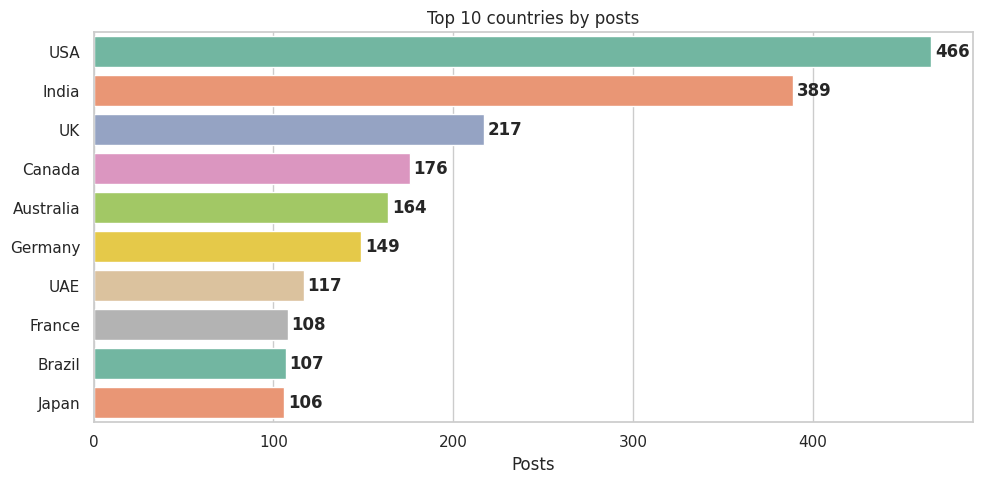

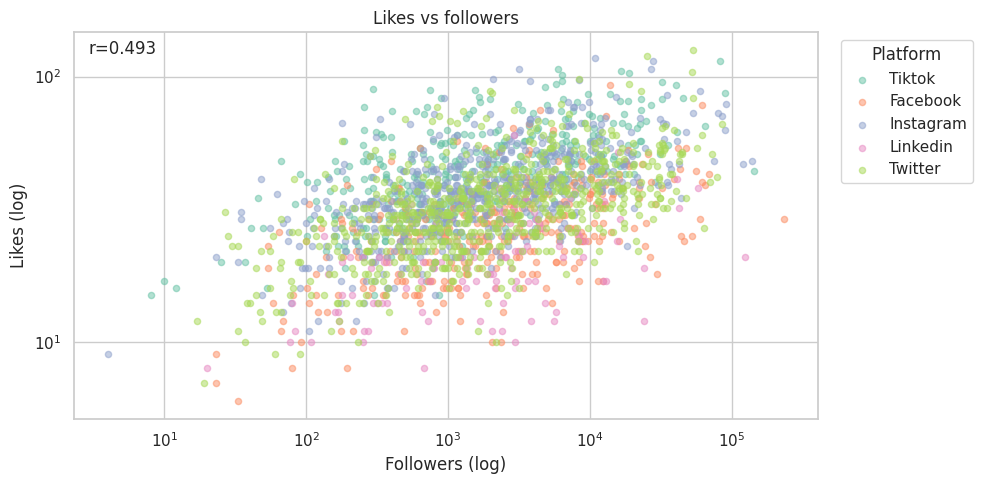

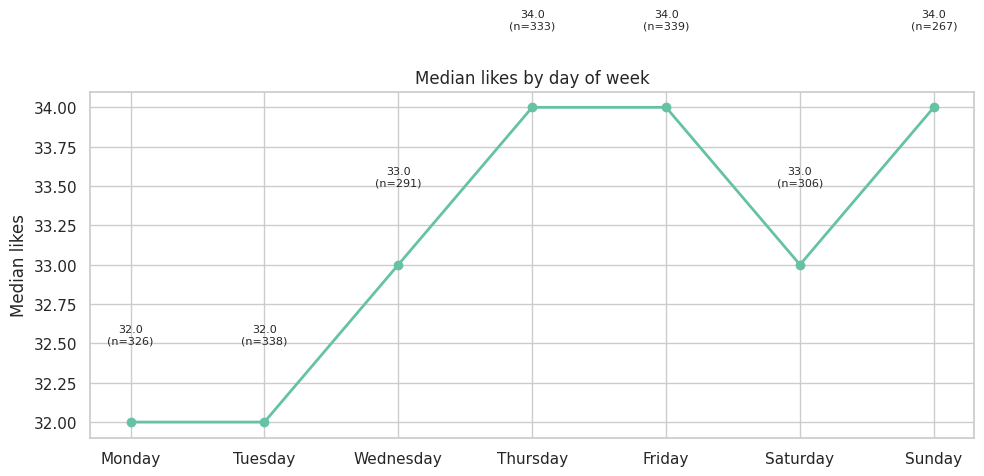


FINDINGS
1. Platform: Tiktok = 44.0 median likes (n=390) vs Instagram = 37.0 (n=595)
2. Sentiment: Positive=39.0 vs Negative=32.0 (Δ=+7.0)
3. Day: Best=Thursday (34.0), Worst=Monday (32.0)
4. Followers vs likes: log-log r=0.493
5. Final N=2200, followers_count missing=88



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ NB02 COMPLETE


In [3]:
# ═══════════════════════════════════════════════════════════════
# NB02 — EDA & VISUALIZATIONS (SINGLE CELL)
# ═══════════════════════════════════════════════════════════════
from google.colab import drive, files
drive.mount('/content/drive/')

import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt, seaborn as sns

FIG = "/content/figures"; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)

# ── LOAD ──
df = pd.read_csv("/content/drive/MyDrive/social_media_data_stage1.csv")
print(f"Loaded: {df.shape[0]} × {df.shape[1]}")

# ── CLEAN ──
df["platform"] = df["platform"].astype(str).str.strip().str.title()
df["country"]  = df["country"].astype(str).str.strip().str.title()
df["country"]  = df["country"].replace({"Usa":"USA","Uk":"UK","Uae":"UAE","Nan":np.nan,"None":np.nan})
df["verified"] = df["verified"].astype(str).str.strip().str.title().replace({"Nan":np.nan})
df["sentiment"]= df["sentiment"].astype(str).str.strip().str.title().replace({"Nan":np.nan})
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["day_of_week"] = df["timestamp"].dt.day_name()
df["has_hashtag"] = df["hashtags"].notna() & (df["hashtags"].astype(str).str.strip() != "")

n0 = len(df)
df = df.drop_duplicates(subset=["post_id","platform","timestamp","user","text"], keep="first")
print(f"Dedup: {n0} → {len(df)}")

df.to_csv("/content/drive/MyDrive/social_media_cleaned.csv", index=False)

# ── STATS ──
metrics = ["likes","retweets_shares","comments"]
print("\n=== BY PLATFORM ===")
plat = df.groupby("platform").agg(n=("post_id","count"),
    median_likes=("likes","median"),
    median_shares=("retweets_shares","median"),
    median_comments=("comments","median")).round(2).sort_values("median_likes", ascending=False)
print(plat)

print("\n=== BY SENTIMENT ===")
sent = df.groupby("sentiment").agg(n=("post_id","count"),
    median_likes=("likes","median"),
    median_shares=("retweets_shares","median"),
    median_comments=("comments","median")).round(2)
print(sent)

print("\n=== BY DAY OF WEEK ===")
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
day = df.groupby("day_of_week").agg(n=("post_id","count"),
    median_likes=("likes","median")).reindex(day_order).round(2)
print(day)

print("\n=== BY COUNTRY (top 10) ===")
ctry = df.groupby("country").agg(n=("post_id","count"),
    median_likes=("likes","median")).sort_values("n", ascending=False).head(10).round(2)
print(ctry)

# ── 6 CHARTS ──
fig, ax = plt.subplots()
o = df["platform"].value_counts().index
sns.countplot(data=df, y="platform", order=o, hue="platform", palette="Set2", legend=False, ax=ax)
ax.set_title("Posts by platform"); ax.set_xlabel("Posts"); ax.set_ylabel("")
for i,v in enumerate(df["platform"].value_counts().reindex(o).values):
    ax.text(v+5, i, str(v), va="center", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIG}/chart01.png", dpi=140); plt.show()

fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax,(m,lab) in zip(axes, [("likes","Median likes"),("retweets_shares","Median shares"),("comments","Median comments")]):
    med = df.groupby("platform")[m].median().sort_values(ascending=False)
    med.plot(kind="bar", ax=ax, color=sns.color_palette("Set2", len(med)))
    ax.set_title(lab+" by platform"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    for i,v in enumerate(med.values): ax.text(i, v+0.3, f"{v:.1f}", ha="center", fontweight="bold", fontsize=9)
plt.suptitle("Median engagement by platform", fontweight="bold"); plt.tight_layout()
plt.savefig(f"{FIG}/chart02.png", dpi=140); plt.show()

fig, ax = plt.subplots()
s_o = ["Positive","Neutral","Negative"]
s_d = df[df["sentiment"].isin(s_o)].groupby("sentiment")[metrics].median().reindex(s_o)
s_d.plot(kind="bar", ax=ax, color=sns.color_palette("Set2",3))
ax.set_title("Median engagement by sentiment"); ax.tick_params(axis="x", rotation=0)
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8, padding=2)
plt.tight_layout(); plt.savefig(f"{FIG}/chart03.png", dpi=140); plt.show()

cc = df["country"].value_counts(); top = cc[cc>=30].head(10)
fig, ax = plt.subplots()
sns.barplot(x=top.values, y=top.index, hue=top.index, palette="Set2", legend=False, ax=ax)
ax.set_title("Top 10 countries by posts"); ax.set_xlabel("Posts"); ax.set_ylabel("")
for i,v in enumerate(top.values): ax.text(v+2, i, str(v), va="center", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIG}/chart04.png", dpi=140); plt.show()

sc = df[(df["followers_count"]>0)&(df["likes"]>0)].copy()
fig, ax = plt.subplots(figsize=(10,5))
for p in sc["platform"].unique():
    s = sc[sc["platform"]==p]; ax.scatter(s["followers_count"], s["likes"], label=p, alpha=0.5, s=20)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Followers (log)"); ax.set_ylabel("Likes (log)"); ax.set_title("Likes vs followers")
ax.legend(title="Platform", bbox_to_anchor=(1.02,1), loc="upper left")
r = np.corrcoef(np.log10(sc["followers_count"]), np.log10(sc["likes"]))[0,1]
ax.text(0.02,0.98,f"r={r:.3f}", transform=ax.transAxes, va="top", bbox=dict(boxstyle="round",facecolor="white",alpha=0.8))
plt.tight_layout(); plt.savefig(f"{FIG}/chart05.png", dpi=140); plt.show()

fig, ax = plt.subplots()
ax.plot(day.index, day["median_likes"], marker="o", linewidth=2, color=sns.color_palette("Set2")[0])
ax.set_title("Median likes by day of week"); ax.set_ylabel("Median likes")
for i,(d,v) in enumerate(day["median_likes"].items()): ax.text(i, v+0.5, f"{v:.1f}\n(n={int(day['n'].iloc[i])})", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/chart06.png", dpi=140); plt.show()

# ── FINDINGS ──
print("\n" + "="*65 + "\nFINDINGS\n" + "="*65)
t1, t2 = plat.index[0], plat.index[1]
print(f"1. Platform: {t1} = {plat.loc[t1,'median_likes']} median likes (n={plat.loc[t1,'n']}) vs {t2} = {plat.loc[t2,'median_likes']} (n={plat.loc[t2,'n']})")
try:
    print(f"2. Sentiment: Positive={s_d.loc['Positive','likes']:.1f} vs Negative={s_d.loc['Negative','likes']:.1f} (Δ={s_d.loc['Positive','likes']-s_d.loc['Negative','likes']:+.1f})")
except: pass
bd, wd = day["median_likes"].idxmax(), day["median_likes"].idxmin()
print(f"3. Day: Best={bd} ({day.loc[bd,'median_likes']}), Worst={wd} ({day.loc[wd,'median_likes']})")
print(f"4. Followers vs likes: log-log r={r:.3f}")
print(f"5. Final N={len(df)}, followers_count missing={df['followers_count'].isna().sum()}")

# ── FAST DOWNLOAD ──
print("\nDownloading 6 charts + 1 CSV...")
for f in ["chart01.png","chart02.png","chart03.png","chart04.png","chart05.png","chart06.png"]:
    files.download(f"{FIG}/{f}")

# Save & download stats CSV
plat.to_csv("/content/stats_platform.csv")
sent.to_csv("/content/stats_sentiment.csv")
day.to_csv("/content/stats_day.csv")
ctry.to_csv("/content/stats_country.csv")
files.download("/content/stats_platform.csv")
files.download("/content/stats_sentiment.csv")

print("\n✅ NB02 COMPLETE")